In [9]:
import tensorflow as tf
import matplotlib.pyplot as plt
import keras

data_dir = r"C:\Users\HP\Desktop\GECBH\ML\Asirra_cat vs dogs"
IMG_SIZE = (128, 128)
BATCH_SIZE = 16
train_ds = keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)
val_ds = keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)
print("Classes:", train_ds.class_names)
from tensorflow.keras import layers, models
model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(128, 128, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])
model.summary()
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)
loss, accuracy = model.evaluate(val_ds)
print(f"Validation accuracy: {accuracy * 100:.2f}%")
model.save("cats_dogs_cnn.keras")
print("Model saved successfully!")
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training Results")
plt.legend()
plt.show()
import numpy as np
model = keras.models.load_model("cats_dogs_cnn.keras")
image_path = "100075941.jpg"
img = keras.utils.load_img(
    image_path,
    target_size=(128, 128)
)
img_array = keras.utils.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
prediction = model.predict(img_array)
if prediction[0][0] > 0.5:
    print("Prediction: Dog")
else:
    print("Prediction: Cat")
plt.imshow(img)
plt.axis("off")
plt.show()


FileNotFoundError: [WinError 3] The system cannot find the path specified: 'C:\\Users\\HP\\Desktop\\GECBH\\ML\\Asirra_cat vs dogs'

In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    # Normalize pixel values from 0-255 to 0-1
    layers.Rescaling(1./255, input_shape=(128, 128, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Flatten feature maps
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    # Output: cat or dog
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 128, 128, 3)       0         
                                                                 
 conv2d (Conv2D)             (None, 126, 126, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 63, 63, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 61, 61, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 30, 30, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 28, 28, 128)       7

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10


2026-10-22 09:38:04.502659: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 32514048 exceeds 10% of free system memory.
2026-10-22 09:38:04.634746: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 15241216 exceeds 10% of free system memory.
2026-10-22 09:38:05.947867: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 23482368 exceeds 10% of free system memory.
2026-10-22 09:38:06.523361: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 15241216 exceeds 10% of free system memory.
2026-10-22 09:38:07.047430: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 25719552 exceeds 10% of free system memory.


55/55 [==============================] - 27s 405ms/step - loss: 0.6956 - accuracy: 0.5216 - val_loss: 0.7056 - val_accuracy: 0.0818
Epoch 2/10
55/55 [==============================] - 16s 297ms/step - loss: 0.6856 - accuracy: 0.5477 - val_loss: 0.6423 - val_accuracy: 0.4909
Epoch 3/10
55/55 [==============================] - 18s 335ms/step - loss: 0.6762 - accuracy: 0.5795 - val_loss: 0.7021 - val_accuracy: 0.5455
Epoch 4/10
55/55 [==============================] - 17s 305ms/step - loss: 0.6483 - accuracy: 0.6295 - val_loss: 0.4303 - val_accuracy: 0.8182
Epoch 5/10
55/55 [==============================] - 16s 294ms/step - loss: 0.5789 - accuracy: 0.6852 - val_loss: 0.2600 - val_accuracy: 0.9136
Epoch 6/10
55/55 [==============================] - 16s 295ms/step - loss: 0.5356 - accuracy: 0.7341 - val_loss: 0.7682 - val_accuracy: 0.5364
Epoch 7/10
55/55 [==============================] - 16s 296ms/step - loss: 0.4486 - accuracy: 0.7932 - val_loss: 0.2596 - val_accuracy: 0.8909
Epoch 8/10

14/14 [==============================] - 1s 48ms/step - loss: 0.2171 - accuracy: 0.9318
Validation accuracy: 93.18%
Model saved successfully!


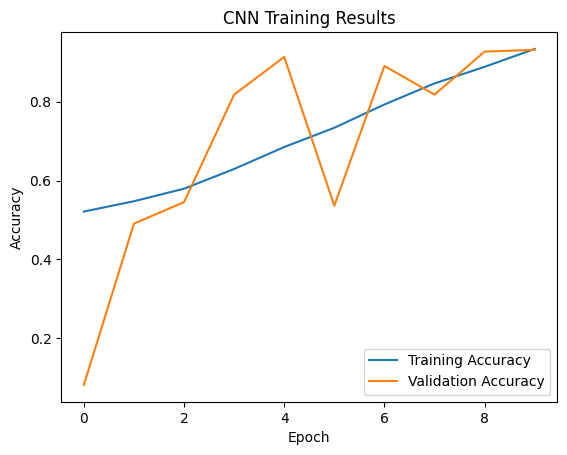

In [ ]:
loss, accuracy = model.evaluate(val_ds)

print(f"Validation accuracy: {accuracy * 100:.2f}%")

model.save("cats_dogs_cnn.keras")

print("Model saved successfully!")

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training Results")
plt.legend()
plt.show()


2026-10-22 09:57:07.827780: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 09:57:09.510388: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 09:57:09.581513: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-22 09:57:16.886621: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


1/1 [==============================] - 0s 336ms/step
Prediction: Cat


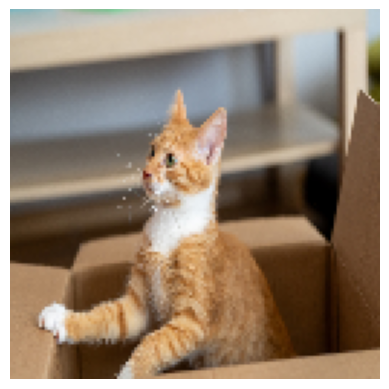

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

model = tf.keras.models.load_model("cats_dogs_cnn.keras")

image_path = "orange_cat_in_cardboard_box.png"

img = tf.keras.utils.load_img(
    image_path,
    target_size=(128, 128)
)
img_array = tf.keras.utils.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
prediction = model.predict(img_array)
if prediction[0][0] > 0.5:
    print("Prediction: Dog")
else:
    print("Prediction: Cat")
plt.imshow(img)
plt.axis("off")
plt.show()